In [1]:
# ---------------------------------------------------------------
# Imports and Configuration
# ---------------------------------------------------------------
from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
SAMPLE_SIZE = 500_000  # training rows for the baseline; adjust if memory allows more/less

INPUT_PATH = Path("feature_selected.parquet")
FEATURE_LIST_PATH = Path("final_feature_cols.json")

In [2]:
# ---------------------------------------------------------------
# Load feature-selected data and the final retained feature list
# ---------------------------------------------------------------
data = pd.read_parquet(INPUT_PATH)
with open(FEATURE_LIST_PATH) as f:
    final_feature_cols = json.load(f)

print(f"Loaded: {data.shape[0]:,} rows, {data.shape[1]} columns")
print(f"Modeling features: {len(final_feature_cols)}")

Loaded: 12,612,960 rows, 56 columns
Modeling features: 50


In [3]:
# ---------------------------------------------------------------
# Resolve the Section 3.5 leakage-suspect columns up front, so the
# "without suspect columns" comparison can be run directly alongside
# the primary baseline rather than bolted on after the fact
# ---------------------------------------------------------------
leakage_suspect_cols = ["CT_RW_TEMP_2", "CT_RW_TEMP_3", "CT_SW_TEMP_2", "CT_SW_TEMP_3"]
suspect_in_final = [c for c in leakage_suspect_cols if c in final_feature_cols]
reduced_feature_cols = [c for c in final_feature_cols if c not in suspect_in_final]

print(f"Leakage-suspect columns retained in final feature set: {suspect_in_final}")
print(f"Reduced feature set (without suspect columns): {len(reduced_feature_cols)} features")

Leakage-suspect columns retained in final feature set: ['CT_RW_TEMP_2', 'CT_SW_TEMP_2', 'CT_SW_TEMP_3']
Reduced feature set (without suspect columns): 47 features


In [4]:
# ---------------------------------------------------------------
# Train/validation/test split — scenario/time-block level, NOT
# random row sampling, per the strong autocorrelation documented
# in Section 4.3 (r=0.994 at 1-minute lag). Contiguous month blocks
# within every source file, rather than holding out entire files,
# to keep every fault_type represented in all three splits even
# for classes with only 1-2 source files.
# ---------------------------------------------------------------
data["month"] = data["Datetime"].dt.month

train_months = list(range(1, 9))   # Jan-Aug
val_months = [9, 10]               # Sep-Oct
test_months = [11, 12]             # Nov-Dec

train_mask = data["month"].isin(train_months)
val_mask = data["month"].isin(val_months)
test_mask = data["month"].isin(test_months)

print(f"Train: {train_mask.sum():,} rows")
print(f"Validation: {val_mask.sum():,} rows")
print(f"Test: {test_mask.sum():,} rows")

for split_name, mask in [("Train", train_mask), ("Validation", val_mask), ("Test", test_mask)]:
    missing = set(data["fault_type"].unique()) - set(data.loc[mask, "fault_type"].unique())
    print(f"{split_name} missing classes: {missing if missing else 'none'}")

Train: 8,396,640 rows
Validation: 2,108,160 rows
Test: 2,108,160 rows
Train missing classes: none
Validation missing classes: none
Test missing classes: none


In [5]:
# ---------------------------------------------------------------
# Stratified subsample of the training set — memory-safe approach.
# Sample row INDICES first using only the lightweight fault_type
# column, so the full 8.4M-row, 50-column training frame is never
# materialized. Only the much smaller sampled subset is later pulled
# with the actual feature columns.
# ---------------------------------------------------------------
fault_type_train = data.loc[train_mask, "fault_type"]
sample_frac = min(1.0, SAMPLE_SIZE / len(fault_type_train))

sampled_index = (
    fault_type_train.groupby(fault_type_train, group_keys=False)
    .apply(lambda s: s.sample(frac=sample_frac, random_state=RANDOM_STATE))
    .index
)

print(f"Sampled {len(sampled_index):,} rows from {len(fault_type_train):,} "
      f"({sample_frac:.1%} of training data)")

del fault_type_train
gc.collect()

Sampled 499,999 rows from 8,396,640 (6.0% of training data)


0

In [6]:
# ---------------------------------------------------------------
# Pull only the sampled rows, with only the needed columns (feature
# columns + label), for both the full and reduced feature sets.
# This is a small frame (SAMPLE_SIZE rows), so no memory ceiling risk.
# ---------------------------------------------------------------
train_sample = data.loc[sampled_index, ["fault_type"] + final_feature_cols]

print(f"train_sample: {len(train_sample):,} rows, {train_sample.shape[1]} columns")
print(train_sample["fault_type"].value_counts(normalize=True).round(3))

train_sample: 499,999 rows, 51 columns
fault_type
chiller_bias                             0.167
coolingtower_bias                        0.167
secondary_chilled_water_pressure_bias    0.167
bypass_leakage                           0.125
coolingtower_fouling                     0.125
bypass_stuck                             0.083
chiller_fouling                          0.083
coolingtower_PI                          0.042
fault_free                               0.042
Name: proportion, dtype: float64


In [7]:
# ---------------------------------------------------------------
# Validation and test sets — smaller splits, pulled directly.
# Cast to float32 throughout to halve memory versus the pandas
# default float64.
# ---------------------------------------------------------------
X_val_full = data.loc[val_mask, final_feature_cols].astype(np.float32)
y_val = data.loc[val_mask, "fault_type"]

X_test_full = data.loc[test_mask, final_feature_cols].astype(np.float32)
y_test = data.loc[test_mask, "fault_type"]

print(f"X_val_full: {X_val_full.shape}, X_test_full: {X_test_full.shape}")

X_val_full: (2108160, 50), X_test_full: (2108160, 50)


In [8]:
# ---------------------------------------------------------------
# Train the primary baseline — Random Forest, full 50-feature set,
# class-weighted to address the imbalance documented in Section 4.1.
# Robust scaling used (not z-score) given the heavy skewness
# documented in Section 4.1.
# ---------------------------------------------------------------
X_train_full = train_sample[final_feature_cols].astype(np.float32)
y_train = train_sample["fault_type"]

scaler_full = RobustScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_val_full_scaled = scaler_full.transform(X_val_full)

baseline_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
baseline_model.fit(X_train_full_scaled, y_train)
print("Baseline model (full feature set) trained.")

Baseline model (full feature set) trained.


In [9]:
# ---------------------------------------------------------------
# Evaluate baseline on validation set — per-class metrics, not just
# aggregate accuracy, per Section VI evaluation criteria
# ---------------------------------------------------------------
y_val_pred = baseline_model.predict(X_val_full_scaled)

print("Validation performance — full feature set:")
print(classification_report(y_val, y_val_pred, digits=3))

Validation performance — full feature set:
                                       precision    recall  f1-score   support

                       bypass_leakage      1.000     1.000     1.000    263520
                         bypass_stuck      1.000     1.000     1.000    175680
                         chiller_bias      0.790     0.843     0.816    351360
                      chiller_fouling      0.905     0.540     0.676    175680
                      coolingtower_PI      0.586     0.127     0.208     87840
                    coolingtower_bias      0.461     0.948     0.621    351360
                 coolingtower_fouling      0.697     0.359     0.474    263520
                           fault_free      0.510     0.018     0.034     87840
secondary_chilled_water_pressure_bias      0.822     0.724     0.770    351360

                             accuracy                          0.723   2108160
                            macro avg      0.752     0.618     0.622   2108160
       

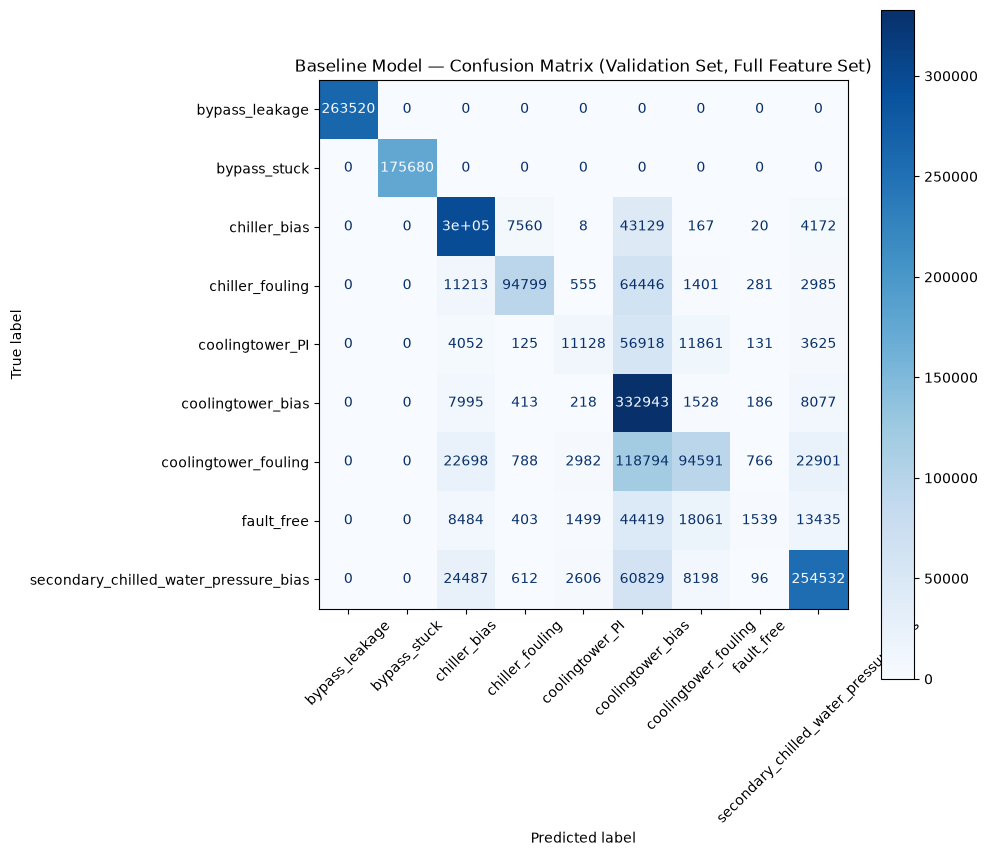

In [10]:
# ---------------------------------------------------------------
# Confusion matrix
# ---------------------------------------------------------------
labels = sorted(y_val.unique())
cm = confusion_matrix(y_val, y_val_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=True
)
ax.set_title("Baseline Model — Confusion Matrix (Validation Set, Full Feature Set)")
plt.tight_layout()
plt.show()

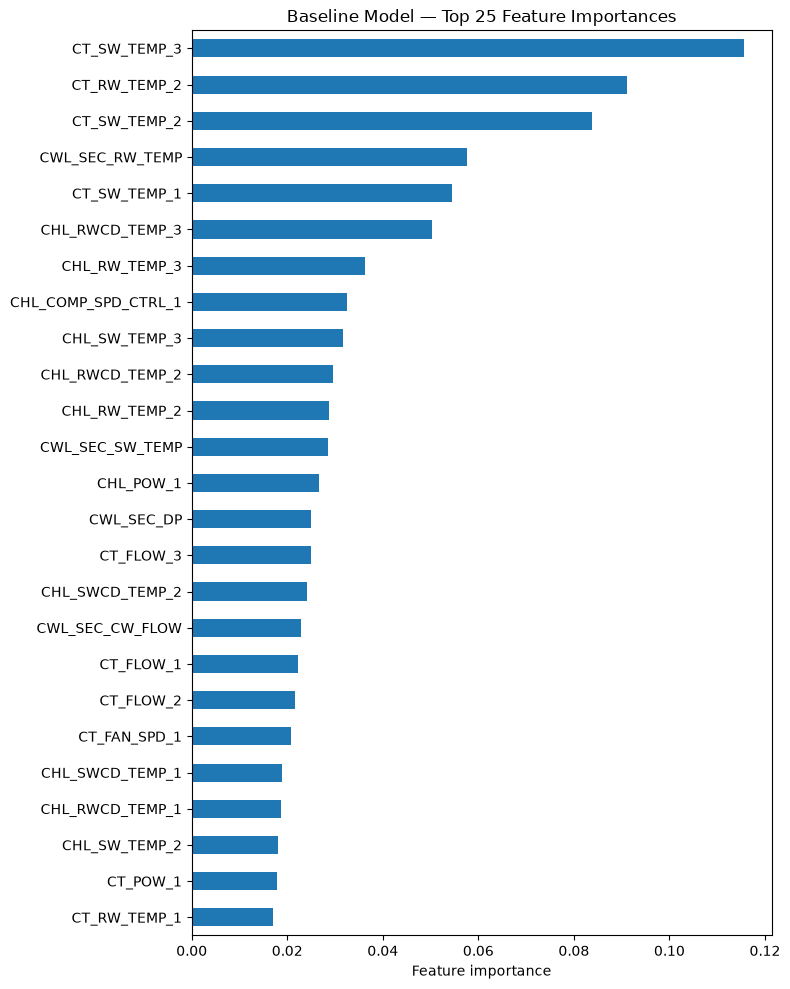

Leakage-suspect column importances:
CT_SW_TEMP_3    0.115629
CT_RW_TEMP_2    0.091048
CT_SW_TEMP_2    0.083704
dtype: float64


In [11]:
# ---------------------------------------------------------------
# Feature importances — check reliance on leakage-suspect columns
# ---------------------------------------------------------------
importances = pd.Series(baseline_model.feature_importances_, index=final_feature_cols)
importances = importances.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
importances.head(25).sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Feature importance")
ax.set_title("Baseline Model — Top 25 Feature Importances")
plt.tight_layout()
plt.show()

if suspect_in_final:
    print("Leakage-suspect column importances:")
    print(importances[importances.index.isin(suspect_in_final)])

In [12]:
# ---------------------------------------------------------------
# Train the comparison model — same procedure, WITHOUT the
# leakage-suspect cooling-tower columns — to directly test the
# Section 3.5 regime-confound concern
# ---------------------------------------------------------------
X_train_reduced = train_sample[reduced_feature_cols].astype(np.float32)
X_val_reduced = X_val_full[reduced_feature_cols]

scaler_reduced = RobustScaler()
X_train_reduced_scaled = scaler_reduced.fit_transform(X_train_reduced)
X_val_reduced_scaled = scaler_reduced.transform(X_val_reduced)

model_reduced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
model_reduced.fit(X_train_reduced_scaled, y_train)
y_val_pred_reduced = model_reduced.predict(X_val_reduced_scaled)

print("Validation performance — WITHOUT leakage-suspect columns:")
print(classification_report(y_val, y_val_pred_reduced, digits=3))

Validation performance — WITHOUT leakage-suspect columns:
                                       precision    recall  f1-score   support

                       bypass_leakage      0.677     0.465     0.552    263520
                         bypass_stuck      0.500     0.802     0.616    175680
                         chiller_bias      0.635     0.925     0.753    351360
                      chiller_fouling      0.859     0.641     0.734    175680
                      coolingtower_PI      0.770     0.246     0.372     87840
                    coolingtower_bias      0.671     0.919     0.775    351360
                 coolingtower_fouling      0.709     0.484     0.575    263520
                           fault_free      0.356     0.026     0.048     87840
secondary_chilled_water_pressure_bias      0.845     0.738     0.788    351360

                             accuracy                          0.680   2108160
                            macro avg      0.669     0.583     0.579   

In [13]:
# ---------------------------------------------------------------
# Direct before/after comparison, focused on the classes where
# cooling-tower-related confusion was concentrated
# ---------------------------------------------------------------
cooling_tower_related = ["coolingtower_bias", "coolingtower_fouling", "coolingtower_PI", "fault_free"]

report_full = classification_report(y_val, y_val_pred, output_dict=True)
report_reduced = classification_report(y_val, y_val_pred_reduced, output_dict=True)

comparison = pd.DataFrame({
    "F1 (with suspect cols)": [report_full[c]["f1-score"] for c in cooling_tower_related],
    "F1 (without suspect cols)": [report_reduced[c]["f1-score"] for c in cooling_tower_related],
    "Overall accuracy": [report_full["accuracy"]] * len(cooling_tower_related),
}, index=cooling_tower_related)
comparison["Overall accuracy (reduced)"] = report_reduced["accuracy"]
comparison["F1 change"] = comparison["F1 (without suspect cols)"] - comparison["F1 (with suspect cols)"]
print(comparison.round(3))

                      F1 (with suspect cols)  F1 (without suspect cols)  Overall accuracy  Overall accuracy (reduced)  F1 change
coolingtower_bias                      0.621                      0.775             0.723                        0.68      0.155
coolingtower_fouling                   0.474                      0.575             0.723                        0.68      0.102
coolingtower_PI                        0.208                      0.372             0.723                        0.68      0.164
fault_free                             0.034                      0.048             0.723                        0.68      0.014


In [14]:
# ---------------------------------------------------------------
# Regime-conditioned evaluation — directly tests whether the
# (full-feature-set) baseline's performance depends on staging
# regime, per Section VI evaluation criteria
# ---------------------------------------------------------------
val_data = data.loc[val_mask, ["n_chillers_on", "fault_type"]].copy() \
    if "n_chillers_on" in data.columns else None

if val_data is None:
    val_data = data.loc[val_mask].copy()
    val_data["n_chillers_on"] = val_data[["CHL_STA_1", "CHL_STA_2", "CHL_STA_3"]].sum(axis=1)
    val_data = val_data[["n_chillers_on", "fault_type"]]

val_data["prediction"] = y_val_pred
val_data["actual"] = y_val.values

for regime in sorted(val_data["n_chillers_on"].unique()):
    subset = val_data[val_data["n_chillers_on"] == regime]
    if len(subset) < 50:
        print(f"n_chillers_on={regime}: insufficient rows ({len(subset)}), skipping")
        continue
    report = classification_report(subset["actual"], subset["prediction"],
                                     output_dict=True, zero_division=0)
    print(f"n_chillers_on={regime} (n={len(subset):,}): "
          f"accuracy={report['accuracy']:.3f}, macro F1={report['macro avg']['f1-score']:.3f}")

n_chillers_on=1.0 (n=1,966,543): accuracy=0.721, macro F1=0.611
n_chillers_on=2.0 (n=140,677): accuracy=0.754, macro F1=0.698
n_chillers_on=3.0 (n=940): accuracy=0.812, macro F1=0.778


In [15]:
# ---------------------------------------------------------------
# Disentangle the two effects: does CT_RW_TEMP_2/CT_SW_TEMP_2/
# CT_SW_TEMP_3's value correlate with bypass fault presence in a
# way that's STABLE across staging regime (genuine signal) or does
# it ALSO show the idle-vs-active collapse pattern found for
# coolingtower_bias (confound)?
# ---------------------------------------------------------------
val_data_check = data.loc[val_mask, suspect_in_final + ["fault_type", "n_chillers_on"]].copy()

for col in suspect_in_final:
    print(f"\n--- {col} by fault_type, split by staging regime ---")
    print(val_data_check.groupby(["fault_type", val_data_check["n_chillers_on"] > 1])[col]
          .mean().unstack().round(2))


--- CT_RW_TEMP_2 by fault_type, split by staging regime ---
n_chillers_on                          False   True 
fault_type                                          
bypass_leakage                         83.47  118.08
bypass_stuck                           68.36     NaN
chiller_bias                           72.96   80.36
chiller_fouling                        73.80   81.00
coolingtower_PI                        72.75   81.35
coolingtower_bias                      72.94   80.71
coolingtower_fouling                   73.09   80.67
fault_free                             73.06   80.41
secondary_chilled_water_pressure_bias  73.14   80.39

--- CT_SW_TEMP_2 by fault_type, split by staging regime ---
n_chillers_on                          False  True 
fault_type                                         
bypass_leakage                         69.83  74.91
bypass_stuck                           68.87    NaN
chiller_bias                           71.16  74.12
chiller_fouling                    

In [16]:
# ---------------------------------------------------------------
# Engineer regime-normalized versions of the three suspect columns:
# deviation from the column's own per-regime mean (computed on
# fault_free as the reference baseline). This should preserve the
# bypass-fault signal (which doesn't track regime) while removing
# the regime-driven noise affecting the other seven classes (whose
# raw values ARE just regime, with no fault-specific content).
# ---------------------------------------------------------------
regime_baseline = (
    data.loc[train_mask & (data["fault_type"] == "fault_free")]
    .groupby("n_chillers_on")[suspect_in_final]
    .mean()
)
print("Regime baseline (from fault_free):")
print(regime_baseline)

for col in suspect_in_final:
    data[f"{col}_regime_dev"] = data[col] - data["n_chillers_on"].map(regime_baseline[col])

print("\nNew columns created:", [f"{c}_regime_dev" for c in suspect_in_final])
print(data.loc[data["fault_type"].isin(["fault_free", "bypass_leakage", "bypass_stuck"]),
               ["fault_type"] + [f"{c}_regime_dev" for c in suspect_in_final]]
      .groupby("fault_type").agg(["mean", "std"]).round(2))

Regime baseline (from fault_free):
               CT_RW_TEMP_2  CT_SW_TEMP_2  CT_SW_TEMP_3
n_chillers_on                                          
1.0               71.774784     71.215917     73.157321
2.0               83.730063     76.916287     80.744350
3.0               89.013725     82.143579     82.831489

New columns created: ['CT_RW_TEMP_2_regime_dev', 'CT_SW_TEMP_2_regime_dev', 'CT_SW_TEMP_3_regime_dev']
               CT_RW_TEMP_2_regime_dev        CT_SW_TEMP_2_regime_dev       CT_SW_TEMP_3_regime_dev      
                                  mean    std                    mean   std                    mean   std
fault_type                                                                                               
bypass_leakage                    5.73  18.81                   -1.78  2.88                   -4.97  0.90
bypass_stuck                     -3.41   0.34                   -2.35  0.83                   -4.29  0.83
fault_free                        0.40   3.49      

In [17]:
# ---------------------------------------------------------------
# Check whether the residual noise in fault_free's regime_dev
# columns is itself explained by outdoor temperature WITHIN regime
# — if so, a finer-grained regime baseline (e.g., binned by OA_TEMP
# as well as staging state) would tighten the normalization further
# ---------------------------------------------------------------
ff_check = data.loc[data["fault_type"] == "fault_free",
                     ["n_chillers_on", "OA_TEMP"] + [f"{c}_regime_dev" for c in suspect_in_final]]

for col in suspect_in_final:
    corr = ff_check.groupby("n_chillers_on").apply(
        lambda g: g["OA_TEMP"].corr(g[f"{col}_regime_dev"])
    )
    print(f"{col}_regime_dev vs OA_TEMP, correlation within each regime:")
    print(corr.round(3))

CT_RW_TEMP_2_regime_dev vs OA_TEMP, correlation within each regime:
n_chillers_on
1.0    0.504
2.0    0.947
3.0    0.946
dtype: float64
CT_SW_TEMP_2_regime_dev vs OA_TEMP, correlation within each regime:
n_chillers_on
1.0    0.388
2.0    0.977
3.0    0.980
dtype: float64
CT_SW_TEMP_3_regime_dev vs OA_TEMP, correlation within each regime:
n_chillers_on
1.0    0.439
2.0    0.299
3.0    0.889
dtype: float64


In [19]:
# ---------------------------------------------------------------
# Most direct test of whether this feature engineering actually
# helps: retrain the baseline with the regime_dev columns added
# ALONGSIDE (not replacing) the original features, and check
# whether bypass_leakage/bypass_stuck recover their near-perfect
# F1 while the other seven classes keep (or improve on) the gains
# seen when the raw suspect columns were dropped
# ---------------------------------------------------------------
engineered_feature_cols = reduced_feature_cols + [f"{c}_regime_dev" for c in suspect_in_final]

needed = ["fault_type"] + engineered_feature_cols
train_sample_eng = data.loc[sampled_index, needed]
val_eng = data.loc[val_mask, needed]

X_train_eng = train_sample_eng[engineered_feature_cols].astype(np.float32)
y_train_eng = train_sample_eng["fault_type"]
X_val_eng = val_eng[engineered_feature_cols].astype(np.float32)

scaler_eng = RobustScaler()
X_train_eng_scaled = scaler_eng.fit_transform(X_train_eng)
X_val_eng_scaled = scaler_eng.transform(X_val_eng)

model_eng = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
)
model_eng.fit(X_train_eng_scaled, y_train_eng)
y_val_pred_eng = model_eng.predict(X_val_eng_scaled)

print("Validation performance — reduced features + regime-normalized columns:")
print(classification_report(y_val, y_val_pred_eng, digits=3))

Validation performance — reduced features + regime-normalized columns:
                                       precision    recall  f1-score   support

                       bypass_leakage      1.000     1.000     1.000    263520
                         bypass_stuck      1.000     1.000     1.000    175680
                         chiller_bias      0.735     0.861     0.793    351360
                      chiller_fouling      0.921     0.558     0.695    175680
                      coolingtower_PI      0.484     0.188     0.271     87840
                    coolingtower_bias      0.510     0.950     0.664    351360
                 coolingtower_fouling      0.808     0.321     0.460    263520
                           fault_free      0.342     0.032     0.058     87840
secondary_chilled_water_pressure_bias      0.768     0.764     0.766    351360

                             accuracy                          0.733   2108160
                            macro avg      0.730     0.631

In [20]:
# ---------------------------------------------------------------
# Build this table programmatically for the notebook / paper,
# rather than transcribing by hand
# ---------------------------------------------------------------
report_full = classification_report(y_val, y_val_pred, output_dict=True)
report_reduced = classification_report(y_val, y_val_pred_reduced, output_dict=True)
report_eng = classification_report(y_val, y_val_pred_eng, output_dict=True)

all_classes = sorted(y_val.unique())
f1_comparison = pd.DataFrame({
    "F1 (Full, 50 feat)": [report_full[c]["f1-score"] for c in all_classes],
    "F1 (Reduced, 47 feat)": [report_reduced[c]["f1-score"] for c in all_classes],
    "F1 (Reduced + regime_dev, 50 feat)": [report_eng[c]["f1-score"] for c in all_classes],
}, index=all_classes)

f1_comparison.loc["Accuracy"] = [report_full["accuracy"], report_reduced["accuracy"], report_eng["accuracy"]]
f1_comparison.loc["Macro F1"] = [
    report_full["macro avg"]["f1-score"],
    report_reduced["macro avg"]["f1-score"],
    report_eng["macro avg"]["f1-score"],
]

print(f1_comparison.round(3))

                                       F1 (Full, 50 feat)  F1 (Reduced, 47 feat)  F1 (Reduced + regime_dev, 50 feat)
bypass_leakage                                      1.000                  0.552                               1.000
bypass_stuck                                        1.000                  0.616                               1.000
chiller_bias                                        0.816                  0.753                               0.793
chiller_fouling                                     0.676                  0.734                               0.695
coolingtower_PI                                     0.208                  0.372                               0.271
coolingtower_bias                                   0.621                  0.775                               0.664
coolingtower_fouling                                0.474                  0.575                               0.460
fault_free                                          0.034       

In [21]:
# ---------------------------------------------------------------
# Save the final engineered dataset (with regime-normalized columns)
# and the final feature list used for the best baseline, so the
# sequence-aware modeling notebook starts from the same corrected
# feature set rather than re-deriving the regime_dev engineering
# ---------------------------------------------------------------
import json

# Full dataset including the three _regime_dev columns
data.to_parquet("baseline_engineered.parquet", index=False)

# The feature list the best (regime_dev) baseline actually used
with open("engineered_feature_cols.json", "w") as f:
    json.dump(engineered_feature_cols, f, indent=2)

# The regime baseline lookup table itself, in case the sequence-aware
# notebook needs to recompute _regime_dev for data outside this split
# (e.g., if windowing changes which rows are included)
regime_baseline.to_csv("regime_baseline_lookup.csv")

print("Saved: baseline_engineered.parquet, engineered_feature_cols.json, regime_baseline_lookup.csv")

Saved: baseline_engineered.parquet, engineered_feature_cols.json, regime_baseline_lookup.csv


In [22]:
# ---------------------------------------------------------------
# Save baseline results for later comparison, so the advanced-model
# notebook doesn't need to retrain all three baseline variants
# ---------------------------------------------------------------
baseline_results = {
    "full": classification_report(y_val, y_val_pred, output_dict=True),
    "reduced": classification_report(y_val, y_val_pred_reduced, output_dict=True),
    "reduced_regime_dev": classification_report(y_val, y_val_pred_eng, output_dict=True),
}

with open("baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=2)

print("Saved: baseline_results.json")

Saved: baseline_results.json
